# Native DSS Records, Backends, and Copy-Out Recovery

This notebook drives RAS Commander's DSS API on the optional native engine,
`ras-commander-fast-dss`, using public HEC data only. It reads and writes real
hydrographs and paired data in DSS6 and DSS7, compares the `java`, `native` and
`shadow` backends, shows the `sync=` flush policies, stores location metadata, and
runs the DSS7 copy-out recovery `RasDss.repair`.

## What you'll learn

- How to check the installed engine and select a `RasDss` backend explicitly
- Regular and irregular time-series round trips to new DSS6 and DSS7 files, and merging into an existing record
- The three `sync=` flush policies of ras-commander-fast-dss 0.1.2, each on its own scratch file
- Reading every curve and label of paired data, and writing a multi-curve record
- Storing and reading location metadata for a boundary series
- What `RasDss.repair` does on a healthy DSS7 file, and what it refuses

## Prerequisites

- `pip install "ras-commander[dss]"` (FAST-DSS and pyjnius). The `java` and
  `shadow` comparison needs Java 8+ and downloads HEC Monolith on first use; set
  `COMPARE_BACKENDS = False` to run without Java.
- No HEC-RAS run. The first run extracts two RasExamples projects and downloads
  two HEC-DSSVue sample files (about 3 MB); later runs use the cache.
- Estimated runtime: 1-3 minutes cached.

## Data

| Example | File | Source |
|---|---|---|
| 1 | `Muncie.dss` (DSS6) | HEC-RAS example project `Muncie` (RasExamples) |
| 1 | `BaldEagleDamBrk.dss` (DSS7) | HEC-RAS example project `BaldEagleCrkMulti2D` (RasExamples) |
| 2 | `sample6.dss` (DSS6), `sample7.dss` (DSS7) | HEC-DSSVue samples, as committed with their SHA-256 in the public fixtures of `ras-commander-fast-dss` v0.1.2 |

Original example files are never modified: every write goes to a new file under
the notebook's working folder.

In [1]:
# Development mode: import repository source when run from a clone.
USE_LOCAL_SOURCE = True

import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name.lower() == "examples" else Path.cwd()
if USE_LOCAL_SOURCE and str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import ras_commander

print(f"ras-commander {ras_commander.__version__} ({'repository source' if USE_LOCAL_SOURCE else 'installed package'})")

ras-commander 0.113.0 (repository source)


In [2]:
from hashlib import sha256
import importlib.metadata
import logging
import os
import shutil
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ras_commander import HdfBndry, RasDss, RasExamples, init_ras_project
from ras_commander.dss import _backend

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")
logging.getLogger("ras_commander").setLevel(logging.WARNING)

COMPARE_BACKENDS = True   # set False to skip the java/shadow comparison (needs Java)

run_root = Path(os.environ.get(
    "RAS_COMMANDER_EXAMPLE_RUN_ROOT",
    repo_root / "working" / "example_321_native_dss_records",
)).resolve()
scratch = run_root / "scratch"
if scratch.exists():
    shutil.rmtree(scratch)
scratch.mkdir(parents=True)


def rel(path) -> str:
    """Path relative to the run root, for printing."""
    path = Path(path).resolve()
    try:
        return path.relative_to(run_root).as_posix()
    except ValueError:
        return path.name


def sha256_file(path) -> str:
    digest = sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("ras-commander-fast-dss", importlib.metadata.version("ras-commander-fast-dss"))
caps = RasDss.get_capabilities()
print("default backend:", RasDss.get_backend())
for key in ("native_installed", "native_writes_available", "native_repair_available",
            "native_write_sync_available", "native_write_sync_modes_available",
            "native_profile_write_available", "native_location_write_available"):
    print(f"  {key}: {caps.attrs[key]}")
caps.set_index("operation").loc[
    ["read_timeseries", "read_paired_data", "write_timeseries", "write_paired_data",
     "repair", "write_location"], ["java", "native", "shadow"]]

ras-commander-fast-dss 0.1.2


default backend: java
  native_installed: True
  native_writes_available: True
  native_repair_available: True
  native_write_sync_available: True
  native_write_sync_modes_available: True
  native_profile_write_available: True
  native_location_write_available: True


,java,native,shadow
operation,,,
read_timeseries,yes,yes,yes
read_paired_data,yes,yes,yes
write_timeseries,yes,gated,java
write_paired_data,yes,gated,java
repair,gated,gated,gated
write_location,gated,gated,gated


## Select the native backend explicitly

`java` remains RAS Commander's default. This notebook sets `RasDss.backend =
"native"` for its core, so no JVM starts until the optional comparison below.
When the environment variable `RAS_COMMANDER_DSS_BACKEND` is set, it overrides
`RasDss.backend`; run this notebook without it.
`native` never falls back to Java: an operation the engine does not support raises
`DssCapabilityError`.

# Example 1: Real hydrographs in DSS6 and DSS7

Muncie stores its boundary and output series in DSS6; BaldEagleCrkMulti2D stores
its boundary-line output series in DSS7. The Muncie series is the upstream inflow
hydrograph at river station 15696.24; the Bald Eagle series is the flow across
the boundary line `DS2NormalD` of the 2D area.

In [3]:
RasDss.backend = "native"

muncie_folder = RasExamples.extract_project("Muncie", output_path=run_root / "projects")
bald_folder = RasExamples.extract_project("BaldEagleCrkMulti2D", output_path=run_root / "projects")
muncie_dss = muncie_folder / "Muncie.dss"
bald_dss = bald_folder / "BaldEagleDamBrk.dss"
assert muncie_dss.is_file() and bald_dss.is_file()
source_hashes = {p.name: sha256_file(p) for p in (muncie_dss, bald_dss)}

rows = []
for path in (muncie_dss, bald_dss):
    catalog = RasDss.get_catalog(path)
    parts = catalog["pathname"].str.split("/", expand=True)
    rows.append({"file": path.name, "dss_version": RasDss.get_file_version(path),
                 "records": len(catalog), "C parts": parts[3].nunique(),
                 "E parts": ", ".join(sorted(parts[5].unique())[:4])})
pd.DataFrame(rows)

,file,dss_version,records,C parts,E parts
0,Muncie.dss,6,1164,24,"01JAN1900 2400, 02JAN1900 0005, 02JAN1900 0010..."
1,BaldEagleDamBrk.dss,7,102,10,1Minute


,series,units,type,values,first,last,peak
0,Muncie (DSS6),CFS,INST-VAL,289,1900-01-02 00:00:00,1900-01-03 00:00:00,21000.000000
1,Bald Eagle (DSS7),cfs,INST-VAL,9973,2018-09-09 00:00:00,2018-09-15 22:12:00,11.125574
2,"Bald Eagle, 6 hours around the peak",cfs,INST-VAL,361,2018-09-10 17:01:00,2018-09-10 23:01:00,11.125574


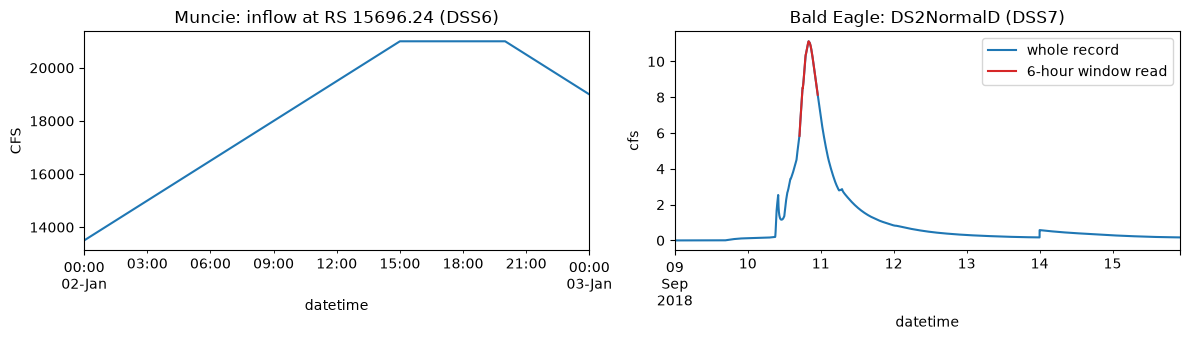

In [4]:
MUNCIE_FLOW = "/WHITE MUNCIE/15696.24/FLOW//5MIN/2D 50FT GRID/"
BALD_FLOW = "/BCLINE/BaldEagleCr: DS2NormalD/FLOW//1Minute/Grid Precip Infiltration/"

muncie_flow = RasDss.read_timeseries(muncie_dss, MUNCIE_FLOW)
bald_flow = RasDss.read_timeseries(bald_dss, BALD_FLOW)
peak_time = bald_flow["value"].idxmax()
window = RasDss.read_timeseries(bald_dss, BALD_FLOW,
                                start_date=peak_time - pd.Timedelta(hours=3),
                                end_date=peak_time + pd.Timedelta(hours=3))

summary = pd.DataFrame([
    {"series": "Muncie (DSS6)", "units": muncie_flow.attrs["units"], "type": muncie_flow.attrs["type"],
     "values": len(muncie_flow), "first": muncie_flow.index[0], "last": muncie_flow.index[-1],
     "peak": muncie_flow["value"].max()},
    {"series": "Bald Eagle (DSS7)", "units": bald_flow.attrs["units"], "type": bald_flow.attrs["type"],
     "values": len(bald_flow), "first": bald_flow.index[0], "last": bald_flow.index[-1],
     "peak": bald_flow["value"].max()},
    {"series": "Bald Eagle, 6 hours around the peak", "units": window.attrs["units"], "type": window.attrs["type"],
     "values": len(window), "first": window.index[0], "last": window.index[-1],
     "peak": window["value"].max()},
])
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
muncie_flow["value"].plot(ax=axes[0], title="Muncie: inflow at RS 15696.24 (DSS6)")
bald_flow["value"].plot(ax=axes[1], title="Bald Eagle: DS2NormalD (DSS7)", label="whole record")
window["value"].plot(ax=axes[1], color="tab:red", label="6-hour window read")
for ax, units in zip(axes, (muncie_flow.attrs["units"], bald_flow.attrs["units"])):
    ax.set_ylabel(units)
axes[1].legend()
plt.tight_layout()

### Regular and irregular round trips to new DSS6 and DSS7 files

The irregular series is an actual selection of the Muncie hydrograph: the stored
values at the times where flow changed by more than 2 % since the last kept value.
Both series are written to a new DSS6 file and a new DSS7 file and read back.

In [5]:
values = muncie_flow["value"].to_numpy()
keep = [0]
for i in range(1, len(values)):
    if abs(values[i] - values[keep[-1]]) > 0.02 * max(abs(values[keep[-1]]), 1.0):
        keep.append(i)
irregular = muncie_flow.iloc[keep]
print(f"irregular selection: {len(irregular)} of {len(muncie_flow)} values")

checks = []
for version in (6, 7):
    target = scratch / f"roundtrip_v{version}.dss"
    RasDss.write_timeseries(target, "/WHITE MUNCIE/15696.24/FLOW//5MIN/REGULAR COPY/",
                            muncie_flow.index, values, units="CFS", data_type="INST-VAL",
                            dss_version=version)
    RasDss.write_timeseries(target, "/WHITE MUNCIE/15696.24/FLOW//IR-MONTH/IRREGULAR SELECTION/",
                            irregular.index, irregular["value"].to_numpy(), units="CFS",
                            data_type="INST-VAL", dss_version=version)
    regular_back = RasDss.read_timeseries(target, "/WHITE MUNCIE/15696.24/FLOW//5MIN/REGULAR COPY/")
    irregular_back = RasDss.read_timeseries(target, "/WHITE MUNCIE/15696.24/FLOW//IR-MONTH/IRREGULAR SELECTION/")
    checks.append({
        "file": rel(target), "version": RasDss.get_file_version(target),
        "regular equal": bool(np.array_equal(regular_back["value"].to_numpy(), values)
                              and regular_back.index.equals(muncie_flow.index)),
        "irregular equal": bool(np.array_equal(irregular_back["value"].to_numpy(), irregular["value"].to_numpy())
                                and irregular_back.index.equals(irregular.index)),
        "records": len(RasDss.get_catalog(target)),
    })
pd.DataFrame(checks)

irregular selection: 26 of 289 values


,file,version,regular equal,irregular equal,records
0,scratch/roundtrip_v6.dss,6,True,True,3
1,scratch/roundtrip_v7.dss,7,True,True,3


### Merge into an existing record

Writing part of a series into an existing record replaces the stored values at the
written times and keeps every other stored value. ras-commander-fast-dss 0.1.2
qualifies the DSS6 merge and extend against HEC's libraries. Here the second half
of the Bald Eagle hydrograph is written, scaled by 1.1, into a copy that holds the
whole hydrograph.

In [6]:
merge_rows = []
for version in (6, 7):
    target = scratch / f"merge_v{version}.dss"
    path = "/BCLINE/DS2NORMALD/FLOW//1MIN/MERGE/"
    RasDss.write_timeseries(target, path, bald_flow.index, bald_flow["value"].to_numpy(),
                            units="CFS", data_type="INST-VAL", dss_version=version)
    half = len(bald_flow) // 2
    replacement = bald_flow.iloc[half:]
    RasDss.write_timeseries(target, path, replacement.index, replacement["value"].to_numpy() * 1.1,
                            units="CFS", data_type="INST-VAL")
    merged = RasDss.read_timeseries(target, path)["value"].to_numpy()
    original = bald_flow["value"].to_numpy()
    merge_rows.append({
        "version": version,
        "kept values unchanged": bool(np.array_equal(merged[:half], original[:half])),
        "written values stored": bool(np.allclose(merged[half:], original[half:] * 1.1)),
        "length": len(merged),
    })
pd.DataFrame(merge_rows)

,version,kept values unchanged,written values stored,length
0,6,True,True,9973
1,7,True,True,9973


### Flush policies (`sync=`)

`sync=` is passed to the engine unchanged. With ras-commander-fast-dss 0.1.2:
`"end"` (the engine default; `True`) flushes once at the end of each write call,
`"step"` flushes at every flush point of the transaction, and `"none"` (`False`)
does not flush. All three make the same writes, so recovery after a killed
process is the same; no policy is a power-loss guarantee. Use `"none"` only for
scratch or regenerable output. Each policy writes its own scratch file here.

In [7]:
sync_rows = []
for mode in ("end", "step", "none"):
    target = scratch / f"sync_{mode}.dss"
    RasDss.write_timeseries(target, "/WHITE MUNCIE/15696.24/FLOW//5MIN/SYNC/", muncie_flow.index,
                            values, units="CFS", data_type="INST-VAL", sync=mode)
    back = RasDss.read_timeseries(target, "/WHITE MUNCIE/15696.24/FLOW//5MIN/SYNC/")["value"].to_numpy()
    sync_rows.append({"sync": mode, "file": rel(target), "values equal": bool(np.array_equal(back, values))})
pd.DataFrame(sync_rows)

,sync,file,values equal
0,end,scratch/sync_end.dss,True
1,step,scratch/sync_step.dss,True
2,none,scratch/sync_none.dss,True


### Backend comparison

The same reads on `java` (HEC Monolith), `native` and `shadow`. `shadow` returns the
native result and logs a comparison with Java for each read. This cell starts a
JVM; it is optional.

In [8]:
if COMPARE_BACKENDS:
    comparison = []
    reference = {}
    for backend in ("native", "java", "shadow"):
        RasDss.backend = backend
        try:
            for name, path, pathname in (("Muncie", muncie_dss, MUNCIE_FLOW), ("Bald Eagle", bald_dss, BALD_FLOW)):
                frame = RasDss.read_timeseries(path, pathname)
                reference.setdefault(name, frame)
                comparison.append({
                    "backend": backend, "series": name, "values": len(frame),
                    "equal to native": bool(np.array_equal(frame["value"].to_numpy(), reference[name]["value"].to_numpy(), equal_nan=True)
                                            and frame.index.equals(reference[name].index)),
                    "units": frame.attrs["units"], "type": frame.attrs["type"],
                })
        except (ImportError, RuntimeError, OSError) as exc:
            comparison.append({"backend": backend, "series": "-", "values": 0,
                               "equal to native": None, "units": type(exc).__name__, "type": "skipped"})
    RasDss.backend = "native"
    display(pd.DataFrame(comparison))
    print("shadow outcomes:", _backend.summary())
else:
    print("Backend comparison skipped (COMPARE_BACKENDS = False).")

,backend,series,values,equal to native,units,type
0,native,Muncie,289,True,CFS,INST-VAL
1,native,Bald Eagle,9973,True,cfs,INST-VAL
2,java,Muncie,289,True,CFS,INST-VAL
3,java,Bald Eagle,9973,True,cfs,INST-VAL
4,shadow,Muncie,289,True,CFS,INST-VAL
5,shadow,Bald Eagle,9973,True,cfs,INST-VAL


shadow outcomes: {'read_timeseries|identical|identical': 2}


# Example 2: HEC-DSSVue samples, paired data, locations and recovery

The HEC-DSSVue sample files hold observed series and paired data in DSS6 and
DSS7. They are fetched from the public fixture folder of the engine's v0.1.2 tag
and checked against their recorded SHA-256 before use.

In [9]:
SAMPLES = {
    "sample6.dss": "977d0c35393ddf8d812a4b9b0bf8d8b38a50b2e0316e035bc9b93bfa730042c8",
    "sample7.dss": "24c912dc4c78b31fe6c4b8cdc4d9f1d19a974454b68b4f06144b494f33f94df6",
}
SAMPLE_URL = "https://raw.githubusercontent.com/gpt-cmdr/ras-commander-fast-dss/v0.1.2/fixtures/public/{}"
sample_dir = run_root / "dssvue_samples"
sample_dir.mkdir(parents=True, exist_ok=True)
samples = {}
for name, expected in SAMPLES.items():
    target = sample_dir / name
    if not target.exists() or sha256_file(target) != expected:
        with urllib.request.urlopen(SAMPLE_URL.format(name), timeout=120) as response:
            target.write_bytes(response.read())
    assert sha256_file(target) == expected, f"{name}: SHA-256 mismatch"
    samples[name] = target
    source_hashes[name] = expected

rows = []
for name, path in samples.items():
    catalog = RasDss.get_catalog(path)
    e_parts = catalog["pathname"].str.split("/").str[5]
    rows.append({"file": name, "dss_version": RasDss.get_file_version(path), "records": len(catalog),
                 "paired data records": int((e_parts == "").sum())})
pd.DataFrame(rows)

,file,dss_version,records,paired data records
0,sample6.dss,6,595,5
1,sample7.dss,7,594,4


In [10]:
RATING = "/MY BASIN/DEER CREEK/STAGE-FLOW///USGS/"
FREQUENCY = "/FISHKILL CREEK/BEACON NY/FREQ-FLOW///USGS/"
rows = []
curves = {}
for name, path in samples.items():
    for pathname in (RATING, FREQUENCY):
        frame = RasDss.read_paired_data(path, pathname)
        curves[(name, pathname)] = frame
        rows.append({"file": name, "record": pathname.split("/")[3], "ordinates": frame.shape[0],
                     "curves": frame.attrs["n_curves"], "x units": frame.attrs["x_units"],
                     "x type": frame.attrs["x_type"], "y units": frame.attrs["y_units"],
                     "y type": frame.attrs["y_type"]})
display(pd.DataFrame(rows))
same = all(np.array_equal(curves[("sample6.dss", p)].to_numpy(), curves[("sample7.dss", p)].to_numpy())
           and np.array_equal(curves[("sample6.dss", p)].index.to_numpy(), curves[("sample7.dss", p)].index.to_numpy())
           for p in (RATING, FREQUENCY))
print("sample6 and sample7 curve values identical:", same)

,file,record,ordinates,curves,x units,x type,y units,y type
0,sample6.dss,STAGE-FLOW,34,1,FEET,UNT,CFS,UNT
1,sample6.dss,FREQ-FLOW,24,1,,PROB,cfs,LOG
2,sample7.dss,STAGE-FLOW,34,1,FEET,UNT,CFS,UNT
3,sample7.dss,FREQ-FLOW,24,1,,,,


sample6 and sample7 curve values identical: True


The values agree between the DSS6 and DSS7 sample, but the stored metadata of the
frequency curve does not: these are the records as HEC stored them in each file.
RAS Commander reports them as stored.

### A multi-curve paired-data record

Muncie stores each plan's maximum water-surface profile as a separate paired-data
record (river station against elevation). The two plans below are written as one
record with two labelled curves, in DSS6 and DSS7, and read back.

,version,curves,labels,values equal,stations equal
0,6,2,"[2D 50FT GRID, 50FT USER N REGIONS]",True,True
1,7,2,"[2D 50FT GRID, 50FT USER N REGIONS]",True,True


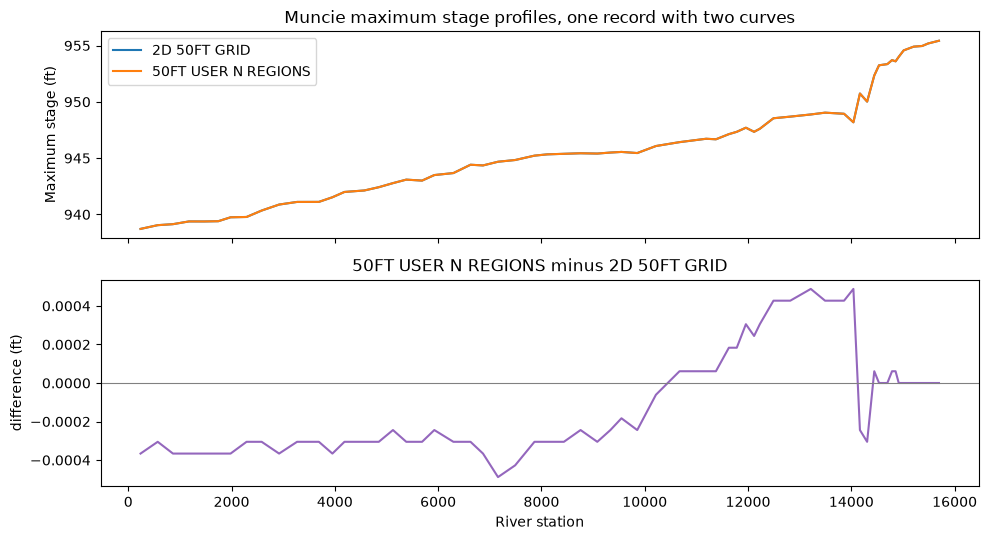

In [11]:
plans = {"2D 50FT GRID": "/WHITE MUNCIE//LOCATION-ELEV//MAX STAGE/2D 50FT GRID/",
         "50FT USER N REGIONS": "/WHITE MUNCIE//LOCATION-ELEV//MAX STAGE/50FT USER N REGIONS/"}
profiles = {label: RasDss.read_paired_data(muncie_dss, pathname) for label, pathname in plans.items()}
stations = profiles["2D 50FT GRID"].index.to_numpy()
assert all(np.array_equal(p.index.to_numpy(), stations) for p in profiles.values())
elevations = np.column_stack([p.iloc[:, 0].to_numpy() for p in profiles.values()])
labels = list(profiles)

pd_rows = []
for version in (6, 7):
    target = scratch / f"max_stage_profiles_v{version}.dss"
    RasDss.write_paired_data(target, "/WHITE MUNCIE//LOCATION-ELEV///MAX STAGE BY PLAN/",
                             stations, elevations, x_units="Riv Sta", x_type="UNT",
                             y_units="FEET", y_type="UNT", labels=labels, dss_version=version)
    back = RasDss.read_paired_data(target, "/WHITE MUNCIE//LOCATION-ELEV///MAX STAGE BY PLAN/")
    pd_rows.append({"version": version, "curves": back.attrs["n_curves"], "labels": back.attrs["labels"],
                    "values equal": bool(np.allclose(back.to_numpy(), elevations)),
                    "stations equal": bool(np.allclose(back.index.to_numpy(), stations))})
display(pd.DataFrame(pd_rows))

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for i, label in enumerate(labels):
    axes[0].plot(stations, elevations[:, i], label=label)
axes[0].set_ylabel("Maximum stage (ft)")
axes[0].set_title("Muncie maximum stage profiles, one record with two curves")
axes[0].legend()
axes[1].plot(stations, elevations[:, 1] - elevations[:, 0], color="tab:purple")
axes[1].axhline(0.0, color="grey", linewidth=0.8)
axes[1].set_ylabel("difference (ft)")
axes[1].set_title(f"{labels[1]} minus {labels[0]}")
axes[1].set_xlabel("River station")
plt.tight_layout()

### Location metadata for a boundary series

`RasDss.write_location` stores coordinates for a series. The coordinates here are
the midpoint of the BaldEagleCrkMulti2D boundary line `DS2NormalD`, read from the
model's geometry HDF through RAS Commander and converted to NAD83 longitude and
latitude. The coordinate-system code fields are left unset; the supplemental text
names the CRS. Written into a copy of the DSS7 boundary file.

In [12]:
ras = init_ras_project(bald_folder, ras_version="7.0", load_results_summary=False, hide_intro=True)
for geom_hdf in (Path(p) for p in ras.geom_df["hdf_path"]):
    if not geom_hdf.is_file():
        continue
    try:
        bc_lines = HdfBndry.get_bc_lines(geom_hdf)
    except Exception:
        continue
    if "Name" in bc_lines and "DS2NormalD" in set(bc_lines["Name"].astype(str).str.strip()):
        break
else:
    raise RuntimeError("no geometry HDF holds the DS2NormalD boundary line")
line = bc_lines.loc[bc_lines["Name"].astype(str).str.strip() == "DS2NormalD"].iloc[0]
midpoint = bc_lines.loc[[line.name]].geometry.interpolate(0.5, normalized=True)
lonlat = midpoint.to_crs("EPSG:4269").iloc[0]
print(f"{rel(geom_hdf)}: CRS {bc_lines.crs.name}; DS2NormalD midpoint {lonlat.x:.5f}, {lonlat.y:.5f}")

location_copy = scratch / "BaldEagleDamBrk_with_location.dss"
shutil.copy2(bald_dss, location_copy)
RasDss.write_location(location_copy, BALD_FLOW, x=round(lonlat.x, 6), y=round(lonlat.y, 6),
                      supplemental="CRS: EPSG:4269 (NAD83 longitude, latitude); "
                                   "midpoint of BC line DS2NormalD from the model geometry HDF")
location = RasDss.read_associated_location(location_copy, BALD_FLOW)
print("stored:", location.x, location.y)
print("supplemental:", location.supplemental)
print("source unchanged:", sha256_file(bald_dss) == source_hashes[bald_dss.name])

2026-11-12 10:12:44 - ras_commander.fast_hdf - WARNING - Ignoring incompatible ras-commander-fast-hdf extension


projects/BaldEagleCrkMulti2D/BaldEagleDamBrk.g08.hdf: CRS NAD83 / Pennsylvania North (ftUS); DS2NormalD midpoint -77.32904, 41.17234
stored: -77.329043 41.172341
supplemental: CRS: EPSG:4269 (NAD83 longitude, latitude); midpoint of BC line DS2NormalD from the model geometry HDF
source unchanged: True


### Record types without public authentic examples

The engine also writes regular profiles, time-series quality and notes, patterns
and pseudo-regular series. The public example files above hold none of these
record types, and this notebook does not manufacture data to show them.
`RasDss.read_profile` and `RasDss.write_profile` wrap the profile functions;
quality, notes and pattern writes are available only through the engine directly.
DSS text records and irregular profiles are not public engine operations.

### Copy-out recovery: `RasDss.repair`

`repair` opens a DSS7 source read-only, copies every readable record its documented
discovery procedure reaches into a new file, verifies each copy, and reports what
it could not copy. **A partial recovery is still published, so always check
`complete` and `not_copied`.** On a healthy file, as here, it shows the mechanics
of the copy-out; it is not evidence about salvaging a damaged file, and a complete
copy is not an integrity certificate. Recovery after a killed writer is covered by
the engine's own tests; power loss is out of scope.

In [13]:
recovered = scratch / "BaldEagleDamBrk_recovered.dss"
result = RasDss.repair(bald_dss, recovered, sync="end")
print("complete:", result["complete"])
print("records copied:", result["records_copied"], "| not copied:", len(result["not_copied"]))
print("source records listed:", result["src_listed_records"])
print("source unchanged:", sha256_file(bald_dss) == source_hashes[bald_dss.name])

src_catalog = set(RasDss.get_catalog(bald_dss)["pathname"])
out_catalog = set(RasDss.get_catalog(recovered)["pathname"])
print("same pathnames:", src_catalog == out_catalog)
diffs = 0
for pathname in sorted(src_catalog)[:20]:
    a = RasDss.read_timeseries(bald_dss, pathname)["value"].to_numpy()
    b = RasDss.read_timeseries(recovered, pathname)["value"].to_numpy()
    diffs += not np.array_equal(a, b, equal_nan=True)
print("value differences in the first 20 records:", diffs)

complete: True
records copied: 102 | not copied: 0
source records listed: 102
source unchanged: True
same pathnames: True


value differences in the first 20 records: 0


In [14]:
refusals = []
for label, call in (
    ("destination exists", lambda: RasDss.repair(bald_dss, recovered)),
    ("DSS6 source", lambda: RasDss.repair(muncie_dss, scratch / "muncie_recovered.dss")),
):
    try:
        call()
        refusals.append({"case": label, "raised": "nothing"})
    except Exception as exc:
        refusals.append({"case": label, "raised": type(exc).__name__})
display(pd.DataFrame(refusals))
print("no DSS6 output left:", not (scratch / "muncie_recovered.dss").exists())

,case,raised
0,destination exists,FileExistsError
1,DSS6 source,DssFormatError


no DSS6 output left: True


## Appendix: engine diagnostics

File signatures and HEC lock status are engine introspection with no RAS Commander
wrapper; they are read directly from `ras_commander_fast_dss` and change nothing.

In [15]:
import ras_commander_fast_dss as fast_dss

rows = []
for path in (muncie_dss, bald_dss, samples["sample6.dss"], samples["sample7.dss"], recovered):
    signature = fast_dss.file_signature(str(path))
    lock = fast_dss.lock_status(str(path))
    rows.append({"file": rel(path), **{k: signature.get(k) for k in ("version", "version_string")},
                 "locked": lock.get("locked")})
display(pd.DataFrame(rows))
print("every source unchanged:", all(sha256_file(p) == source_hashes[p.name]
                                     for p in (muncie_dss, bald_dss, *samples.values())))

,file,version,version_string,locked
0,projects/Muncie/Muncie.dss,6,6-UF,False
1,projects/BaldEagleCrkMulti2D/BaldEagleDamBrk.dss,7,7-HL,False
2,dssvue_samples/sample6.dss,6,6-SB,False
3,dssvue_samples/sample7.dss,7,7-10,False
4,scratch/BaldEagleDamBrk_recovered.dss,7,7-JA,False


every source unchanged: True


## Key takeaways

- `java` stays the default backend; select `native` explicitly. `native` never falls back to Java.
- Regular and irregular series, merges and multi-curve paired data round-trip in DSS6 and DSS7.
- `sync=` is the engine's flush policy, passed through unchanged; `"none"` is for regenerable output only.
- `RasDss.repair` publishes partial recoveries: check `complete` and `not_copied`. It refuses an existing destination and DSS6 sources.
- Close any `ras_commander_fast_dss.DssFile` session that has written before renaming, replacing or deleting its file.

See [DSS Read and Write Backends](https://rascommander.info/ras/user-guide/dss-native-backend/) and the
[native engine page](https://rascommander.info/ras/native-engine/#dss-engine).